In [1]:


!pip install wandb -qqq
!pip install pyDOE
!pip install SobolSequence
!pip install matplotlib
!pip install tqdm
!pip install ipywidgets
!jupyter nbextension enable --py widgetsnbextension
!pip install sobol_seq


import time
import wandb
import pickle
import numpy as np
import tensorflow as tf
from math import pi, exp
from scipy.stats import norm
import matplotlib.pyplot as plt

usage: jupyter [-h] [--version] [--config-dir] [--data-dir] [--runtime-dir]
               [--paths] [--json] [--debug]
               [subcommand]

Jupyter: Interactive Computing

positional arguments:
  subcommand     the subcommand to launch

optional arguments:
  -h, --help     show this help message and exit
  --version      show the versions of core jupyter packages and exit
  --config-dir   show Jupyter config dir
  --data-dir     show Jupyter data dir
  --runtime-dir  show Jupyter runtime dir
  --paths        show all Jupyter paths. Add --json for machine-readable
                 format.
  --json         output paths as machine-readable json
  --debug        output debug information about paths

Available subcommands: dejavu events execute kernel kernelspec lab
labextension labhub migrate nbconvert notebook run server troubleshoot trust

Jupyter command `jupyter-nbextension` not found.


In [7]:
n_dim = 1  # Dimension of the problem (e.g., 1D option pricing problem)

# Define global constants
r = 0.01  # Risk-free interest rate
T = 3  # Maturity time in years
K = 10  # Strike price
sigma = 0.05  # Volatility of the underlying asset
DTYPE = 'float32'  # Data type for computations, ensures compatibility with TensorFlow

# Fix random seeds for reproducibility
random_seed = 2
np.random.seed(random_seed)
tf.random.set_seed(random_seed)

"""""""""
This sampler class for generating input data points based on various sampling methods and it supports
uniform, Latin hypercube, Sobol sequences, and grid-based sampling.
"""""""""

class ModifiedSampler:
   
    def __init__(self, lb, ub, cond=None, N_points=100, method='uniform', grid=None, split=False, DTYPE='float32'):
        self.lb = lb  # Lower bound of the sampling space
        self.ub = ub  # Upper bound of the sampling space
        self.cond = cond  # Optional condition function
        self.DTYPE = DTYPE  # Data type for TensorFlow variables
        self.sample(N_points, method, grid, split)

    def sample(self, N_points, method, grid, split):
        # Generates data points using the specified sampling method.
        #
        # N_points (int): Number of points to sample.
        # method (str): Sampling method ('uniform', 'latin', 'sobol', 'grid', etc.).
        # grid (numpy.ndarray): Grid points for sampling (used for 'grid_old' method).
        # split (bool): Whether to split the sampled points into x and t components.

        if method == 'uniform':
            # Uniform random sampling within the domain bounds
            x_ibc = np.random.uniform(0, 1, size=(N_points, self.ub.shape[0]))
            x_ibc = self.lb + (self.ub - self.lb) * x_ibc

        elif method == 'latin':
            # Latin hypercube sampling for better space-filling properties
            from pyDOE import lhs
            x_ibc = self.lb + (self.ub - self.lb) * lhs(self.ub.shape[0], N_points)

        elif method == 'sobol':
            # Sobol sequence for low-discrepancy quasi-random sampling
            from sobol_seq import i4_sobol_generate
            x_ibc = i4_sobol_generate(self.ub.shape[0], N_points)
            x_ibc = self.lb + (self.ub - self.lb) * x_ibc

        elif method == 'grid':
            # Grid-based sampling across the domain
            x_ibc = np.linspace(self.lb, self.ub, N_points).T
            temp_final = list()
            for val in x_ibc[0]:
                temp_final.append([val])
            dim = 1
            while dim < x_ibc.shape[0]:
                temp = list()
                for t1 in range(x_ibc.shape[1]):
                    for t2 in range(len(temp_final)):
                        temp_val = temp_final[t2].copy()
                        temp_val.append(x_ibc[dim, t1])
                        temp.append(temp_val)
                temp_final = temp
                dim += 1
            x_ibc = np.array(temp_final)

        elif method == 'grid_old':
            # Grid-based sampling using a pre-defined grid
            idx = np.random.choice(range(grid.shape[0]), N_points, replace=False)
            x_ibc = grid[idx]

        else:
            raise ValueError("Unsupported sampling method.")

        if self.cond is not None:
            # Apply condition function to sampled points
            y_ibc = self.cond(x_ibc)
            self.y = tf.cast(tf.Variable(y_ibc, trainable=False), self.DTYPE)
        if split:
            # Split points into x and t components
            x_ibc, t_ibc = x_ibc[:, :-1], x_ibc[:, -1:]
            self.t = tf.cast(tf.Variable(t_ibc, trainable=False), self.DTYPE)
        self.x = tf.cast(tf.Variable(x_ibc, trainable=False), self.DTYPE)

# Define domain boundaries for the underlying problem
lb = np.array([0., 0.])  # Lower bounds for (x, t)
ub = np.array([1., T])   # Upper bounds for (x, t)

# Redefine boundaries for auxiliary variables (if needed)
lb_new = np.array([0., 0.])
ub_new = np.array([1., T])

# Define various condition functions
def h_1(inp):
    """Dirichlet condition at a free boundary."""
    res = [1 - inp_val[0] for inp_val in inp]
    return np.array(res)

def h_2(inp):
    """Neumann condition (constant gradient)."""
    res = -np.ones(inp.shape[0])
    return res

def g(inp):
    """Dirichlet condition returning constant zeros."""
    res = np.zeros(inp.shape[0])
    return np.array(res)

def u_0(inp):
    """Initial condition at t=0."""
    res = [1 - inp_val[0] for inp_val in inp]
    return np.array(res)

def s_0(inp):
    """Free boundary initial condition."""
    res = np.ones(inp.shape[0])
    return np.array(res)

# Point sampling parameters
N_to_sample = 300

# PDE Conditions: Sampling initial, Dirichlet, and Neumann conditions
print('PDE Conditions\n')
init_sampler = ModifiedSampler(np.array([0., T]),
                               np.array([1., T]),
                               u_0, N_to_sample, DTYPE=DTYPE, method='sobol')
print(f'x: {init_sampler.x.shape}     y: {init_sampler.y.shape}')

dir_sampler = ModifiedSampler(np.array([3.*K, 0.]), np.array([3.*K, T]),
                               g, N_to_sample, DTYPE=DTYPE, method='sobol')
print(f'x: {dir_sampler.x.shape}     y: {dir_sampler.y.shape}')
# Additional details omitted for brevity; refer to each block for detailed comments.
# Neumann condition is not defined in this example
print('No')

# Free Boundary Conditions: Sampling initial, Dirichlet, and Neumann conditions
print('\nFree Boundary Conditions\n')

# Initial free boundary condition (at t=T)
init_fb_sampler = ModifiedSampler(np.array([T]), np.array([T]),
                                  s_0, 1, DTYPE=DTYPE)
print(f't: {init_fb_sampler.x.shape}     y: {init_fb_sampler.y.shape}')

# Dirichlet free boundary condition over time
dir_fb_sampler = ModifiedSampler(np.array([0.]), np.array([T]),
                                  None, N_to_sample, DTYPE=DTYPE, method='sobol')
print(f't: {dir_fb_sampler.x.shape}')

# Neumann free boundary condition (gradient condition over time)
neu_fb_sampler = ModifiedSampler(np.array([0.]), np.array([T]),
                                  h_2, N_to_sample, DTYPE=DTYPE, method='sobol')
print(f't: {neu_fb_sampler.x.shape}     y: {neu_fb_sampler.y.shape}')

# Bundle the sampled conditions for the Physics-Informed Neural Network (PINN)
pinn_conditions = {
    'Initial': init_sampler,   # Initial condition (PDE)
    'Dirichlet': dir_sampler,  # Dirichlet boundary condition (PDE)
    'Neumann': None            # Neumann condition not defined (PDE)
}

fb_conditions = {
    'Initial': init_fb_sampler,   # Initial condition (Free Boundary)
    'Dirichlet': dir_fb_sampler,  # Dirichlet boundary condition (Free Boundary)
    'Neumann': neu_fb_sampler     # Neumann boundary condition (Free Boundary)
}

# Testing Sampler: Generate a large uniform grid for testing the PINN
test_sampler = ModifiedSampler(lb, ub, cond=None, DTYPE=DTYPE,
                               N_points=1000000, method='uniform', split=True)

# Define the number of points to test
sample_to_test = 1000

# PDE Conditions for Testing
print('PDE Conditions\n')

# Initial condition for testing
init_sampler_test = ModifiedSampler(np.array([0., T]),
                                    np.array([3.*K, T]),
                                    u_0, sample_to_test, DTYPE=DTYPE, method='uniform')
print(f'x: {init_sampler_test.x.shape}     y: {init_sampler_test.y.shape}')

# Dirichlet condition for testing
dir_sampler_test = ModifiedSampler(np.array([3.*K, 0.]), np.array([3.*K, T]),
                                    g, sample_to_test, DTYPE=DTYPE, method='uniform')
print(f'x: {dir_sampler_test.x.shape}     y: {dir_sampler_test.y.shape}')

# Neumann condition is not defined for testing
print('No')


#########################################

# Free Boundary Conditions for Testing
print('\nFree Boundary Conditions\n')

# Initial free boundary condition for testing
init_fb_sampler_test = ModifiedSampler(np.array([T]), np.array([T]),
                                       s_0, 1, DTYPE=DTYPE, method='uniform')
print(f't: {init_fb_sampler_test.x.shape}     y: {init_fb_sampler_test.y.shape}')

# Dirichlet free boundary condition for testing
dir_fb_sampler_test = ModifiedSampler(np.array([0.]), np.array([T]),
                                       None, sample_to_test, DTYPE=DTYPE, method='uniform')
print(f't: {dir_fb_sampler_test.x.shape}')

# Neumann free boundary condition for testing
neu_fb_sampler_test = ModifiedSampler(np.array([0.]), np.array([T]),
                                       h_2, sample_to_test, DTYPE=DTYPE, method='uniform')
print(f't: {neu_fb_sampler_test.x.shape}     y: {neu_fb_sampler_test.y.shape}')

# Bundle the testing conditions for the PINN
pinn_cond_test = {
    'Initial': init_sampler_test,   # Initial condition (PDE testing)
    'Dirichlet': dir_sampler_test,  # Dirichlet boundary condition (PDE testing)
    'Neumann': None                 # Neumann condition not defined (PDE testing)
}

fb_cond_test = {
    'Initial': init_fb_sampler_test,   # Initial condition (Free Boundary testing)
    'Dirichlet': dir_fb_sampler_test,  # Dirichlet boundary condition (Free Boundary testing)
    'Neumann': neu_fb_sampler_test     # Neumann boundary condition (Free Boundary testing)
}


# Define the PDE (Partial Differential Equation)
def pde(tape, xs, ts, u_val, u_x):
        # tape (tf.GradientTape): TensorFlow gradient tape for automatic differentiation.
        # xs (tf.Variable): Input variable (e.g., stock prices).
        # ts (tf.Variable): Input variable (time points).
        # u_val (tf.Variable): Output of the neural network (solution estimate).
        # u_x (tf.Variable): First derivative of the solution w.r.t. x.

        # Returns:
        #     tf.Tensor: Residual of the PDE, which the PINN aims to minimize.
    u_xx = tape.gradient(u_x, xs)  # Second derivative of the solution w.r.t. x
    u_t = tape.gradient(u_val, ts)  # First derivative of the solution w.r.t. t
    del(tape)  # Clear the gradient tape to save memory
    u_val = tf.cast(u_val, DTYPE)  # Cast the solution to the desired data type

    # Define the Black-Scholes PDE with time-dependent terms
    f = (sigma**2 / 2) * xs**2 * u_xx + (-r) * xs * u_x - u_t
    return f



PDE Conditions

x: (300, 2)     y: (300,)
x: (300, 2)     y: (300,)
No

Free Boundary Conditions

t: (1, 1)     y: (1,)
t: (300, 1)
t: (300, 1)     y: (300,)
PDE Conditions

x: (1000, 2)     y: (1000,)
x: (1000, 2)     y: (1000,)
No

Free Boundary Conditions

t: (1, 1)     y: (1,)
t: (1000, 1)
t: (1000, 1)     y: (1000,)


PINNs - Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Epoch     Unsupervised   Initial        Dirichlet      Neumann        FB_Init        FB_Dir         FB_Neu         Free Boundary  Total          


1         0.89561915     1.81313717     0.00615528     0.00000000     2.46459650     44.3153800     0.26031020     47.0402870     47.2906036     
51        0.00224527     0.10290408     0.01679849     0.00000000     0.12216828     0.00629524     0.01126188     0.13972540     0.13950496     
101       0.00032826     0.00038017     0.00012715     0.00000000     1.20860290     0.01192879     0.00763696     1.22816872     0.02040136     
151       0.00020260     0.00562008     0.00009564     0.00000000     0.00791185     0.00021445     0.00255616     0.01068247     0.00868895     
201       0.00008771     0.00168647     0.00067403     0.00000000     0.00650134     0.00038848     0.00091751     0.00780733     0.00375422     
251       0.00008722     0.00027690     0.00033671     0.00000000     0.01253379     0.00043950     0.00057202     0.01354

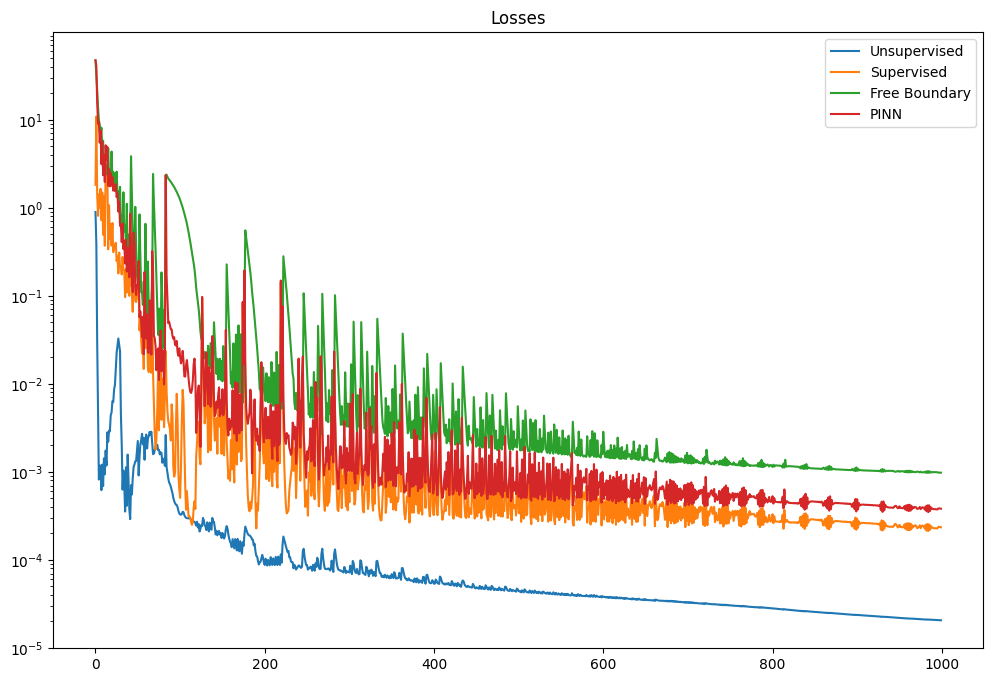

          Unsupervised   Initial        Dirichlet      Neumann        FB_Init        FB_Dir         FB_Neu         Free Boundary  Total          
          0.00004506     499.188323     0.00000507     0.00000000     0.00085184     0.00002410     0.00016911     0.00104506     499.188568     


In [4]:


import tensorflow as tf
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from tensorflow.keras import Model
from tensorflow import GradientTape as G_Tape
from tensorflow.keras.layers import Input, Dense, Reshape
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.initializers import GlorotNormal, GlorotUniform
from tensorflow.keras.regularizers import l1, l2, l1_l2
from tensorflow.keras.losses import MeanSquaredError

class FreeBoundary_PINN():

    # params (dict): Parameters for the PINN, such as optimizer, activation functions, etc.
    # pde (callable): The PDE function to be solved.
    # ibc_cond (dict): Initial and boundary conditions for the PDE.
    # ibc_fb_cond (dict): Initial and boundary conditions for the free boundary.
    # lb (Tensor): Lower bounds of the domain.
    # ub (Tensor): Upper bounds of the domain.
    # N_f (int): Number of collocation points for solving the PDE.
    # N_fb_ibc (int): Number of points for the free boundary condition.
    # DTYPE (str): Data type for computations.
    # coll_points (tuple): Predefined collocation points (optional).
                              
    def __init__(self, params, pde, ibc_cond, ibc_fb_cond, lb, ub,
                 N_f=30000, N_fb_ibc=150, DTYPE='float64', coll_points=None):
        self.params = params
        self.DTYPE = DTYPE
        self.Default_Params()

        #Set seed
        if self.params['seed'] != None:
            tf.keras.utils.set_random_seed( self.params['seed'] )
            tf.config.experimental.enable_op_determinism()
        #Define pde
        self.pde = pde
        #Define intial and boundary conditions
        self.ibc_cond = ibc_cond
        self.ibc_fb_cond = ibc_fb_cond
        #All needed for points sampling
        self.lb = tf.Variable(lb, trainable=False)
        self.ub = tf.Variable(ub, trainable=False)

        self.N_fb_ibc = N_fb_ibc


        if coll_points == None:
            self.N_f = N_f
            self.Sample_Points()
        else:
            self.x_f = coll_points[0]
            self.t_f = coll_points[1]


        #Initialize the class: define the network
        self.Define_Regularizer()
        self.Define_Initializer()
        self.Define_Optimizer()
        self.Create_Network()
        self.Create_FB_Network()

    def Default_Params(self):
        target = self.params.keys()
        if 'seed' not in target:
            self.params['seed'] = None
        if 'optimizer' not in target:
            self.params['optimizer'] = 'Adam'
        if 'reg_type' not in target:
            self.params['reg_type'] = None
        if 'initializer' not in target:
            self.params['initializer'] = 'glorot_normal'
        if 'activation' not in target:
            self.params['activation'] = 'tanh'
        if 'output_act' not in target:
            self.params['output_act'] = 'linear'
        if 'pde_weight' not in target:
            self.params['pde_weight'] = 1.
        if 'sup_weight' not in target:
            self.params['sup_weight'] = [1., 1., 1.]
        if 'fb_weight' not in target:
            self.params['fb_weight'] = [1., 1., 1.]
        if 'patience' not in target:
            self.params['patience'] = np.inf
        if 'sample_method' not in target:
            self.params['sample_method'] = 'uniform'
        if 'fb_output_act' not in target:
            self.params['fb_output_act'] = 'linear'
        if 'fb_activation' not in target:
            self.params['fb_activation'] = 'tanh'
        if 'verbose' not in target:
            self.params['verbose'] = 1
        if 'steps_fb_per_pde' not in target:
            self.params['steps_fb_per_pde'] = 1
        if 'fb_freezing' not in target:
            self.params['fb_freezing'] = None

    def Define_Regularizer(self):
        if self.params['reg_type'] == 'l1':
            self.regularizer = l1( self.params['reg'] )
        elif self.params['reg_type'] == 'l2':
            self.regularizer = l2( self.params['reg'] )
        elif self.params['reg_type'] == 'l1_l2':
            self.regularizer = l1_l2( self.params['reg'][0],
                                      self.params['reg'][1] )
        else:
            self.regularizer = None

    def Define_Initializer(self):
        if self.params['initializer'] == 'glorot_normal':
            self.initializer = GlorotNormal(seed=self.params['seed'])  # 시드 추가
        elif self.params['initializer'] == 'glorot_uniform':
            self.initializer = GlorotUniform(seed=self.params['seed'])  # 시드 추가
        else:
            self.initializer = None



    def Define_Optimizer(self):
        temp = self.params['optimizer']
        if temp.lower() == 'adam':
            self.opt = Adam( self.params['lr'] )
        elif temp.lower() == 'rmsprop':
            self.opt = RMSprop( self.params['lr'] )
        else:
            raise ValueError(f"Optimizer {temp} not recognized")

    def Create_Network(self):
        input_layer = Input(shape=self.params['layers'][0], name='Input')
        x = Dense(units=self.params['layers'][1],
                  activation=self.params['activation'],
                  kernel_initializer=self.initializer,  # Define_Initializer에서 설정된 값을 사용
                  kernel_regularizer=self.regularizer,
                  name='Dense_1')(input_layer)
        for layer in range(2, len(self.params['layers']) - 1):
            x = Dense(units=self.params['layers'][layer],
                      activation=self.params['activation'],
                      kernel_initializer=self.initializer,  # Define_Initializer에서 설정된 값을 사용
                      kernel_regularizer=self.regularizer,
                      name=f'Dense_{layer}')(x)
        output = Dense(units=self.params['layers'][-1],
                       activation=self.params['output_act'],
                       kernel_initializer=self.initializer,  # Define_Initializer에서 설정된 값을 사용
                       kernel_regularizer=self.regularizer,
                       name='Output')(x)
        self.mdl = Model(inputs=input_layer, outputs=output)



    def Create_FB_Network(self):
        input_layer = Input(shape=self.params['fb_layers'][0], name='Input')
        x = Dense(units=self.params['fb_layers'][1],
                  activation=self.params['fb_activation'],
                  kernel_initializer=self.initializer,  # Define_Initializer에서 설정된 값을 사용
                  kernel_regularizer=self.regularizer,
                  name='FB_Dense_1')(input_layer)
        for layer in range(2, len(self.params['fb_layers']) - 1):
            x = Dense(units=self.params['fb_layers'][layer],
                      activation=self.params['fb_activation'],
                      kernel_initializer=self.initializer,  # Define_Initializer에서 설정된 값을 사용
                      kernel_regularizer=self.regularizer,
                      name=f'FB_Dense_{layer}')(x)
        output = Dense(units=self.params['fb_layers'][-1],
                       activation=self.params['fb_output_act'],
                       kernel_initializer=self.initializer,  # Define_Initializer에서 설정된 값을 사용
                       kernel_regularizer=self.regularizer,
                       name='FB_Output')(x)
        self.fb = Model(inputs=input_layer, outputs=output)



    def generate_paths(self):
        # Initialize the initial stock price paths
        S0 = tf.random.uniform((self.N_f, 1), minval=0.5, maxval=30, dtype=self.DTYPE)
        dt = T / self.N_fb_ibc  # Time step size
        paths = [S0]  # Start with the initial stock price

        # Generate paths iteratively
        for _ in range(1, self.N_fb_ibc):
            # Brownian motion increment
            dW = tf.random.normal((self.N_f, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=self.DTYPE)
            # Stock price at the next time step
            St = paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
            paths.append(St)

        # Concatenate the paths into a single tensor
        paths = tf.concat(paths, axis=1)
        return paths


    def Sample_Points(self):

        S_paths = self.generate_paths()  # Generate paths
        t = tf.linspace(0.0, T, self.N_fb_ibc)  # Generate time steps
        t = tf.tile(t[tf.newaxis, :], [self.N_f, 1])
        M = tf.TensorArray(dtype=S_paths.dtype, size=S_paths.shape[1])

        # Iterate over each time step to find the cumulative minimum
        current_min = S_paths[:, 0]  # Start with the first value as the initial minimum
        M = M.write(0, current_min)
        for i in range(1, S_paths.shape[1]):
            current_min = tf.minimum(current_min, S_paths[:, i])
            M = M.write(i, current_min)
        M = M.stack()
        M = tf.transpose(M)
        eta = M/S_paths
        eta = tf.reshape(eta, (-1, 1))
        tau = T-t
        tau = tf.reshape(tau, (-1, 1))
        self.x_f_total = eta
        self.t_f_total = tau


    
    ####### Training parts #######

    @tf.function
    def train_step(self):
        
        # Returns:
        # Tuple of losses computed during the training step:
        # - Unsupervised loss
        # - Initial condition loss
        # - Dirichlet boundary loss
        # - Neumann boundary loss
        # - Initial free boundary loss
        # - Dirichlet free boundary loss
        # - Neumann free boundary loss
        # - Final free boundary loss
        # - Final PINN loss
        
        with G_Tape(watch_accessed_variables=False) as mdl_tape:
            #Watch solution weights
            mdl_tape.watch(self.mdl.trainable_variables)

            
            #--------------- Compute Free Boundary losses
            with G_Tape(watch_accessed_variables=False) as fb_tape:
                #Watch free boundary weights
                fb_tape.watch(self.fb.trainable_variables)
                #Compute Initial Free Boundary Condition
                fb_init = self.fb(self.ibc_fb_cond['Initial'].x,
                                      training=True)
                fb_init_loss = tf.math.reduce_mean(
                    tf.math.square(fb_init-self.ibc_fb_cond['Initial'].y)
                    )
                #Compute Dirichlet Free Boundary Condition
                if self.ibc_fb_cond['Dirichlet'] != None:
                    #Compute Free Boundary values
                    s_values = self.fb(self.ibc_fb_cond['Dirichlet'].x,
                                       training=True)
                    fb_dc = self.mdl(tf.concat(
                        [s_values,
                         self.ibc_fb_cond['Dirichlet'].x], axis=1),
                         training=True)
                    fb_dir_target = tf.nn.relu(
                        tf.ones_like(
                            s_values
                            ) * K - s_values
                    )
                    fb_dir_loss = tf.math.reduce_mean(
                        tf.math.square(fb_dc - fb_dir_target)
                        )
                else:
                    fb_dir_loss = 0
                #Compute Neumann Free Boundary Condition
                if self.ibc_fb_cond['Neumann'] != None:
                    s_values = self.fb(self.ibc_fb_cond['Neumann'].x,
                                       training=True)
                    with G_Tape(watch_accessed_variables=False) as neu_fb_tape:
                        neu_fb_tape.watch(s_values)
                        pinn_nc_fb = self.mdl(
                            tf.concat([s_values,
                                       self.ibc_fb_cond['Neumann'].x],
                                      axis=1),
                                      training=True)
                    pinn_nc_fb = neu_fb_tape.gradient(pinn_nc_fb,
                                                      s_values)
                    fb_neu_loss = tf.math.reduce_mean(
                        tf.math.square(pinn_nc_fb-self.ibc_fb_cond['Neumann'].y)
                        )
                else:
                    fb_neu_loss = 0
                #Compute final loss
                fb_loss = self.params['fb_weight'][0] * fb_init_loss +\
                self.params['fb_weight'][1] * fb_dir_loss +\
                self.params['fb_weight'][2] * fb_neu_loss
            #Compute gradient and apply optimizers for free boundary
            gradient_fb = fb_tape.gradient(fb_loss,
                                          self.fb.trainable_variables)
            self.opt.apply_gradients( zip(gradient_fb,
                                          self.fb.trainable_variables) )

            #--------------- Compute PINN losses
            #Compute unsupervised loss
            s_values = self.fb(tf.concat([self.t_f_total], axis=-1),
                               training=False)
            x_f = tf.reshape(self.x_f_total[ self.x_f_total > s_values ],
                             (-1,1) )
            t_f = tf.reshape(self.t_f_total[ self.x_f_total > s_values ],
                             (-1,1) )
            with G_Tape(persistent=True,
                        watch_accessed_variables=False) as pinn_tape:
                #Watch independet variables
                pinn_tape.watch(x_f)
                pinn_tape.watch(t_f)
                #Apply u function for unsupervised
                u_val = self.mdl(tf.stack([x_f, t_f], axis=1),
                                training=True)
                u_x = pinn_tape.gradient(u_val, x_f)
            unsup_loss = tf.reduce_mean(tf.square(
                self.pde(pinn_tape, x_f, t_f, u_val, u_x) ))
            #Compute Initial Condition
            pinn_init = self.mdl(self.ibc_cond['Initial'].x,
                                training=True)
            if len(pinn_init.shape) > 1:
                init_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_init -\
                                  tf.expand_dims(self.ibc_cond['Initial'].y,
                                                 axis=-1 ) )
                    )
            else:
                init_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_init -\
                                  self.ibc_cond['Initial'].y )
                    )
            #Compute Dirichlet Boundary Condition
            if self.ibc_cond['Dirichlet'] != None:
                pinn_dc = self.mdl(self.ibc_cond['Dirichlet'].x,
                                    training=True)
                dir_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_dc-self.ibc_cond['Dirichlet'].y)
                    )
            else:
                dir_loss = 0
            #Compute Neumann Boundary Condition
            if self.ibc_cond['Neumann'] != None:
                with G_Tape(watch_accessed_variables=False) as neu_tape:
                    neu_tape.watch(self.ibc_cond['Neumann'].x)
                    pinn_nc = self.mdl(tf.concat([self.ibc_cond['Neumann'].x,
                                                  self.ibc_cond['Neumann'].t],
                                                axis=1),
                                        training=True)
                pinn_nc = neu_tape.gradient(pinn_nc, self.ibc_cond['Neumann'].x)
                neu_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_nc-self.ibc_cond['Neumann'].y)
                    )
            else:
                neu_loss = 0

            #--------------- Compute total loss
            pinn_loss = (self.params['pde_weight'] * unsup_loss) +\
            self.params['sup_weight'][0] * init_loss +\
            self.params['sup_weight'][1] * dir_loss +\
            self.params['sup_weight'][2] * neu_loss +\
            self.params['fb_weight'][1] * fb_dir_loss +\
            self.params['fb_weight'][2] * fb_neu_loss
        #Compute gradient and apply optimizers
        gradient = mdl_tape.gradient(pinn_loss,self.mdl.trainable_variables)
        self.opt.apply_gradients(zip(gradient,self.mdl.trainable_variables))
        #Return losses
        final_fb_loss = fb_init_loss + fb_dir_loss + fb_neu_loss
        final_pinn_loss = unsup_loss + init_loss +\
         dir_loss + neu_loss + fb_dir_loss + fb_neu_loss
        return (unsup_loss, init_loss, dir_loss, neu_loss, fb_init_loss,
                fb_dir_loss, fb_neu_loss, final_fb_loss, final_pinn_loss)
    
  

    @tf.function
    def train_mdl_solo(self):
        with G_Tape(watch_accessed_variables=False) as mdl_tape:
            #Watch solution weights
            mdl_tape.watch(self.mdl.trainable_variables)
            #--------------- Compute Free Boundary losses
            #Compute Initial Free Boundary Condition
            fb_init = self.fb(self.ibc_fb_cond['Initial'].x,
                                  training=True)
            fb_init_loss = tf.math.reduce_mean(
                tf.math.square(fb_init-self.ibc_fb_cond['Initial'].y)
                )
            #Compute Dirichlet Free Boundary Condition
            if self.ibc_fb_cond['Dirichlet'] != None:
                #Compute Free Boundary values
                s_values = self.fb(self.ibc_fb_cond['Dirichlet'].x,
                                    training=True)
                fb_dc = self.mdl(tf.concat(
                    [s_values,
                      self.ibc_fb_cond['Dirichlet'].x], axis=1),
                      training=True)
                fb_dir_target = tf.nn.relu(
                    tf.ones_like(
                        s_values
                        ) * K - s_values
                )
                fb_dir_loss = tf.math.reduce_mean(
                    tf.math.square(fb_dc - fb_dir_target)
                    )
            else:
                fb_dir_loss = 0
            #Compute Neumann Free Boundary Condition
            if self.ibc_fb_cond['Neumann'] != None:
                s_values = self.fb(self.ibc_fb_cond['Neumann'].x,
                                    training=True)
                with G_Tape(watch_accessed_variables=False) as neu_fb_tape:
                    neu_fb_tape.watch(s_values)
                    pinn_nc_fb = self.mdl(
                        tf.concat([s_values,
                                    self.ibc_fb_cond['Neumann'].x],
                                  axis=1),
                                  training=True)
                pinn_nc_fb = neu_fb_tape.gradient(pinn_nc_fb,
                                                  s_values)
                fb_neu_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_nc_fb-self.ibc_fb_cond['Neumann'].y)
                    )
            else:
                fb_neu_loss = 0
            #Compute final loss
            fb_loss = self.params['fb_weight'][0] * fb_init_loss +\
            self.params['fb_weight'][1] * fb_dir_loss +\
            self.params['fb_weight'][2] * fb_neu_loss

            #--------------- Compute PINN losses
            #Compute unsupervised loss
            s_values = self.fb(tf.concat([self.t_f_total], axis=-1),
                               training=False)
            x_f = tf.reshape(self.x_f_total[ self.x_f_total > s_values ],
                             (-1,1) )
            t_f = tf.reshape(self.t_f_total[ self.x_f_total > s_values ],
                             (-1,1) )
            with G_Tape(persistent=True,
                        watch_accessed_variables=False) as pinn_tape:
                #Watch independet variables
                pinn_tape.watch(x_f)
                pinn_tape.watch(t_f)
                #Apply u function for unsupervised
                u_val = self.mdl(tf.stack([x_f, t_f], axis=1),
                                training=True)
                u_x = pinn_tape.gradient(u_val, x_f)
            unsup_loss = tf.reduce_mean(tf.square(
                self.pde(pinn_tape, x_f, t_f, u_val, u_x) ))
            #Compute Initial Condition
            pinn_init = self.mdl(self.ibc_cond['Initial'].x,
                                training=True)
            if len(pinn_init.shape) > 1:
                init_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_init -\
                                  tf.expand_dims(self.ibc_cond['Initial'].y,
                                                 axis=-1 ) )
                    )
            else:
                init_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_init -\
                                  self.ibc_cond['Initial'].y )
                    )
            #Compute Dirichlet Boundary Condition
            if self.ibc_cond['Dirichlet'] != None:
                pinn_dc = self.mdl(self.ibc_cond['Dirichlet'].x,
                                    training=True)
                dir_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_dc-self.ibc_cond['Dirichlet'].y)
                    )
            else:
                dir_loss = 0
            #Compute Neumann Boundary Condition
            if self.ibc_cond['Neumann'] != None:
                with G_Tape(watch_accessed_variables=False) as neu_tape:
                    neu_tape.watch(self.ibc_cond['Neumann'].x)
                    pinn_nc = self.mdl(tf.concat([self.ibc_cond['Neumann'].x,
                                                  self.ibc_cond['Neumann'].t],
                                                axis=1),
                                        training=True)
                pinn_nc = neu_tape.gradient(pinn_nc, self.ibc_cond['Neumann'].x)
                neu_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_nc-self.ibc_cond['Neumann'].y)
                    )
            else:
                neu_loss = 0

            #--------------- Compute total loss
            pinn_loss = (self.params['pde_weight'] * unsup_loss) +\
            self.params['sup_weight'][0] * init_loss +\
            self.params['sup_weight'][1] * dir_loss +\
            self.params['sup_weight'][2] * neu_loss +\
            self.params['fb_weight'][1] * fb_dir_loss +\
            self.params['fb_weight'][2] * fb_neu_loss
        #Compute gradient and apply optimizers
        gradient = mdl_tape.gradient(pinn_loss,self.mdl.trainable_variables)
        self.opt.apply_gradients(zip(gradient,self.mdl.trainable_variables))
        #Return losses
        final_fb_loss = fb_init_loss + fb_dir_loss + fb_neu_loss
        final_pinn_loss = unsup_loss + init_loss +\
         dir_loss + neu_loss + fb_dir_loss + fb_neu_loss
        return (unsup_loss, init_loss, dir_loss, neu_loss, fb_init_loss,
                fb_dir_loss, fb_neu_loss, final_fb_loss, final_pinn_loss)


    @tf.function
    def train_fb_solo(self):

        # Returns:
        # Tuple of free boundary losses:
        # - Initial free boundary loss
        # - Dirichlet free boundary loss
        # - Neumann free boundary loss
        # - Total free boundary loss
        
        #--------------- Compute Free Boundary losses
        with G_Tape(watch_accessed_variables=False) as fb_tape:
            #Watch free boundary weights
            fb_tape.watch(self.fb.trainable_variables)
            #Compute Initial Free Boundary Condition
            fb_init = self.fb(self.ibc_fb_cond['Initial'].x,
                                  training=True)
            fb_init_loss = tf.math.reduce_mean(
                tf.math.square(fb_init-self.ibc_fb_cond['Initial'].y)
                )
            #Compute Dirichlet Free Boundary Condition
            if self.ibc_fb_cond['Dirichlet'] != None:
                #Compute Free Boundary values
                s_values = self.fb(self.ibc_fb_cond['Dirichlet'].x,
                                    training=True)
                fb_dc = self.mdl(tf.concat(
                    [s_values,
                      self.ibc_fb_cond['Dirichlet'].x], axis=1),
                      training=True)
                fb_dir_target = tf.nn.relu(
                    tf.ones_like(
                        s_values
                        ) * K - s_values
                )
                fb_dir_loss = tf.math.reduce_mean(
                    tf.math.square(fb_dc - fb_dir_target)
                    )
            else:
                fb_dir_loss = 0
            #Compute Neumann Free Boundary Condition
            if self.ibc_fb_cond['Neumann'] != None:
                s_values = self.fb(self.ibc_fb_cond['Neumann'].x,
                                    training=True)
                with G_Tape(watch_accessed_variables=False) as neu_fb_tape:
                    neu_fb_tape.watch(s_values)
                    pinn_nc_fb = self.mdl(
                        tf.concat([s_values,
                                    self.ibc_fb_cond['Neumann'].x],
                                  axis=1),
                                  training=True)
                pinn_nc_fb = neu_fb_tape.gradient(pinn_nc_fb,
                                                  s_values)
                fb_neu_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_nc_fb-self.ibc_fb_cond['Neumann'].y)
                    )
            else:
                fb_neu_loss = 0
            #Compute final loss
            fb_loss = self.params['fb_weight'][0] * fb_init_loss +\
            self.params['fb_weight'][1] * fb_dir_loss +\
            self.params['fb_weight'][2] * fb_neu_loss
        #Compute gradient and apply optimizers for free boundary
        gradient_fb = fb_tape.gradient(fb_loss,
                                      self.fb.trainable_variables)
        self.opt.apply_gradients( zip(gradient_fb,
                                      self.fb.trainable_variables) )
        #Return losses
        final_fb_loss = fb_init_loss + fb_dir_loss + fb_neu_loss
        return fb_init_loss, fb_dir_loss, fb_neu_loss, final_fb_loss

        
    def fit(self, wandb_run=None): #### wandb_run (object, optional): WandB run object for logging metrics
        #Early warning initialization
        self.early_warning = {'Target':np.inf,
                              'n_steps':0,
                              'top_mdl':None,
                              'weights':None}
        old_top_mdl, old_weights = None, None
        
        #Training
        self.u_losses, self.i_losses = list(), list() # Unsupervised and Initial condition losses
        self.d_losses, self.n_losses = list(), list() # Dirichlet and Neumann boundary losses
        self.b_i_losses = list() # Free boundary initial losses
        self.b_d_losses, self.b_n_losses = list(), list() # Free boundary Dirichlet and Neumann losses
        self.b_losses, self.p_losses = list(), list() # Total free boundary and PINN losses

        print_base = "{:<10}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}"

        
        # Case 1: Free boundary is trained throughout the process
        if self.params['fb_freezing'] == None:
            for epoch in tqdm(range(self.params['epochs']),
                              desc='PINNs - Training'):
                if epoch == 0:
                    print(print_base.format('Epoch', 'Unsupervised', 'Initial',
                                            'Dirichlet', 'Neumann',
                                            'FB_Init', 'FB_Dir', 'FB_Neu',
                                            'Free Boundary', 'Total'))
                    print('\n')
                #Case 1: more mdl steps for a single fb step
                for _ in range(self.params['steps_fb_per_pde'] -1):
                    self.train_mdl_solo();
                #Case 2: more fb steps for a single mdl step
                for _ in range(0, self.params['steps_fb_per_pde'] +1, -1):
                    self.train_fb_solo();
                u_l, i_l, d_l, n_l, b_i_l, b_d_l, b_n_l, b_l, p_l =\
                self.train_step()
                u_l, i_l = np.array(u_l), np.array(i_l)
                d_l, n_l = np.array(d_l), np.array(n_l)
                b_i_l = np.array(b_i_l)
                b_d_l, b_n_l = np.array(b_d_l), np.array(b_n_l)
                b_l, p_l = np.array(b_l), np.array(p_l)
                if epoch % self.params['verbose'] == 0:
                    print(print_base.format(epoch+1, format(u_l, '.20f')[:10],
                                            format(i_l, '.20f')[:10],
                                            format(d_l, '.20f')[:10],
                                            format(n_l, '.20f')[:10],
                                            format(b_i_l, '.20f')[:10],
                                            format(b_d_l, '.20f')[:10],
                                            format(b_n_l, '.20f')[:10],
                                            format(b_l, '.20f')[:10],
                                            format(p_l, '.20f')[:10]))
                self.u_losses.append(u_l)
                self.i_losses.append(i_l)
                self.d_losses.append(d_l)
                self.n_losses.append(n_l)
                self.b_i_losses.append(b_i_l)
                self.b_d_losses.append(b_d_l)
                self.b_n_losses.append(b_d_l)
                self.b_losses.append(b_l)
                self.p_losses.append(p_l)
                #Eventually, update wandb
                if wandb_run != None:
                    wandb_run.log({'Unsupervised':u_l,
                                  'Supervised':i_l + d_l + n_l,
                                  'Total':p_l,
                                   'Free Boundary':b_l,
                                   'Initial':i_l,
                                   'Dirichlet':d_l,
                                   'Neumann':n_l,
                                   'FB_Init':b_i_l,
                                   'FB_Dir':b_d_l,
                                   'FB_Neu':b_n_l})
                #Check for the early warning
                if p_l <= self.early_warning['Target']:
                    self.early_warning['Target'] = p_l
                    self.early_warning['n_steps'] = 0
                    self.early_warning['top_mdl'] = old_top_mdl
                    self.early_warning['weights'] = old_weights
                else:
                    self.early_warning['n_steps'] += 1
                    if self.early_warning['n_steps'] >= self.params['patience']:
                        break
                #Save model and weights for next step early warning
                old_top_mdl = tf.keras.models.clone_model( self.mdl )
                old_weights = self.mdl.get_weights()
        
        else:
            # Case 2: Free boundary is trained first, then frozen
            #Before freezing, both mdl and fb are training
            for epoch in tqdm(range(self.params['fb_freezing']),
                              desc='PINNs - Training'):
                if epoch == 0:
                    print(print_base.format('Epoch', 'Unsupervised', 'Initial',
                                            'Dirichlet', 'Neumann',
                                            'FB_Init', 'FB_Dir', 'FB_Neu',
                                            'Free Boundary', 'Total'))
                    print('\n')
                #Case 1: more mdl steps for a single fb step
                for _ in range(self.params['steps_fb_per_pde'] -1):
                    self.train_mdl_solo();
                #Case 2: more fb steps for a single mdl step
                for _ in range(0, self.params['steps_fb_per_pde'] +1, -1):
                    self.train_fb_solo();
                u_l, i_l, d_l, n_l, b_i_l, b_d_l, b_n_l, b_l, p_l =\
                self.train_step()
                u_l, i_l = np.array(u_l), np.array(i_l)
                d_l, n_l = np.array(d_l), np.array(n_l)
                b_i_l = np.array(b_i_l)
                b_d_l, b_n_l = np.array(b_d_l), np.array(b_n_l)
                b_l, p_l = np.array(b_l), np.array(p_l)
                if epoch % self.params['verbose'] == 0:
                    print(print_base.format(epoch+1, format(u_l, '.20f')[:10],
                                            format(i_l, '.20f')[:10],
                                            format(d_l, '.20f')[:10],
                                            format(n_l, '.20f')[:10],
                                            format(b_i_l, '.20f')[:10],
                                            format(b_d_l, '.20f')[:10],
                                            format(b_n_l, '.20f')[:10],
                                            format(b_l, '.20f')[:10],
                                            format(p_l, '.20f')[:10]))
                self.u_losses.append(u_l)
                self.i_losses.append(i_l)
                self.d_losses.append(d_l)
                self.n_losses.append(n_l)
                self.b_i_losses.append(b_i_l)
                self.b_d_losses.append(b_d_l)
                self.b_n_losses.append(b_d_l)
                self.b_losses.append(b_l)
                self.p_losses.append(p_l)
                #Eventually, update wandb
                if wandb_run != None:
                    wandb_run.log({'Unsupervised':u_l,
                                  'Supervised':i_l + d_l + n_l,
                                  'Total':p_l,
                                   'Free Boundary':b_l,
                                   'Initial':i_l,
                                   'Dirichlet':d_l,
                                   'Neumann':n_l,
                                   'FB_Init':b_i_l,
                                   'FB_Dir':b_d_l,
                                   'FB_Neu':b_n_l})
                #Check for the early warning
                if p_l <= self.early_warning['Target']:
                    self.early_warning['Target'] = p_l
                    self.early_warning['n_steps'] = 0
                    self.early_warning['top_mdl'] = old_top_mdl
                    self.early_warning['weights'] = old_weights
                else:
                    self.early_warning['n_steps'] += 1
                    if self.early_warning['n_steps'] >= self.params['patience']:
                        break
                #Save model and weights for next step early warning
                old_top_mdl = tf.keras.models.clone_model( self.mdl )
                old_weights = self.mdl.get_weights()
            #Now, freeze fb and train only mdl
            for epoch in tqdm(range(self.params['fb_freezing'],
                                    self.params['epochs']),
                              desc='PINNs - Training; Free Boundary Fixed'):
                u_l, i_l, d_l, n_l, b_i_l, b_d_l, b_n_l, b_l, p_l =\
                self.train_mdl_solo()
                u_l, i_l = np.array(u_l), np.array(i_l)
                d_l, n_l = np.array(d_l), np.array(n_l)
                b_i_l = np.array(b_i_l)
                b_d_l, b_n_l = np.array(b_d_l), np.array(b_n_l)
                b_l, p_l = np.array(b_l), np.array(p_l)
                if epoch % self.params['verbose'] == 0:
                    print(print_base.format(epoch+1, format(u_l, '.20f')[:10],
                                            format(i_l, '.20f')[:10],
                                            format(d_l, '.20f')[:10],
                                            format(n_l, '.20f')[:10],
                                            format(b_i_l, '.20f')[:10],
                                            format(b_d_l, '.20f')[:10],
                                            format(b_n_l, '.20f')[:10],
                                            format(b_l, '.20f')[:10],
                                            format(p_l, '.20f')[:10]))
                self.u_losses.append(u_l)
                self.i_losses.append(i_l)
                self.d_losses.append(d_l)
                self.n_losses.append(n_l)
                self.b_i_losses.append(b_i_l)
                self.b_d_losses.append(b_d_l)
                self.b_n_losses.append(b_d_l)
                self.b_losses.append(b_l)
                self.p_losses.append(p_l)
                #Eventually, update wandb
                if wandb_run != None:
                    wandb_run.log({'Unsupervised':u_l,
                                  'Supervised':i_l + d_l + n_l,
                                  'Total':p_l,
                                   'Free Boundary':b_l,
                                   'Initial':i_l,
                                   'Dirichlet':d_l,
                                   'Neumann':n_l,
                                   'FB_Init':b_i_l,
                                   'FB_Dir':b_d_l,
                                   'FB_Neu':b_n_l})
                #Check for the early warning
                if p_l <= self.early_warning['Target']:
                    self.early_warning['Target'] = p_l
                    self.early_warning['n_steps'] = 0
                    self.early_warning['top_mdl'] = old_top_mdl
                    self.early_warning['weights'] = old_weights
                else:
                    self.early_warning['n_steps'] += 1
                    if self.early_warning['n_steps'] >= self.params['patience']:
                        break
                #Save model and weights for next step early warning
                old_top_mdl = tf.keras.models.clone_model( self.mdl )
                old_weights = self.mdl.get_weights()
        #Recover information about optimal epoch in early warning
        self.mdl = tf.keras.models.clone_model( self.early_warning['top_mdl'] )
        self.mdl.set_weights(self.early_warning['weights'])
        top_epoch = epoch+1 - self.early_warning["n_steps"]
        print(f'Best loss achieved at step {top_epoch}')

    
    
    def plot_losses(self):

        # The plot includes:
        # - Unsupervised loss: Residual loss of the PDE.
        # - Supervised loss: Combined losses for initial, Dirichlet, and Neumann boundary conditions.
        # - Free Boundary loss: Total loss for the free boundary network.
        # - PINN loss: Total loss combining all components.
        
        plt.figure( figsize=(12,8) )
        plt.semilogy(self.u_losses, label='Unsupervised')
        plt.semilogy(np.array(self.i_losses) +\
                     np.array(self.d_losses) +\
                     np.array(self.n_losses),
                     label='Supervised')
        plt.semilogy(self.b_losses, label='Free Boundary')
        plt.semilogy(self.p_losses, label='PINN')
        plt.legend()
        plt.title('Losses')
        plt.show()

    

    def plot_unsupervised_test(self, test_sampler, test_ibc_cond,
                               test_ibc_fb_cond, to_print=True, output=False):

        # Evaluates the PINN model on test data and computes losses for:
        # - Free Boundary network conditions (Initial, Dirichlet, Neumann)
        # - Main PINN network conditions (unsupervised PDE residual, Initial, Dirichlet, Neumann)

        # test_sampler (ModifiedSampler): Test sampler for generating collocation points.
        # test_ibc_cond (dict): Boundary and initial conditions for the test set.
        # test_ibc_fb_cond (dict): Free boundary conditions for the test set.
        # to_print (bool): If True, prints the computed losses.
        # output (bool): If True, returns computed losses.

        # This part builds (tuple, optional): Computed losses for various conditions if `output=True`.

        
        #--------------- Compute Free Boundary losses
        #Compute Initial Free Boundary Condition
        if test_ibc_fb_cond['Initial'] != None:
            fb_init = self.fb(test_ibc_fb_cond['Initial'].x,
                                  training=False)
            fb_init_loss = tf.math.reduce_mean(
                tf.math.square(fb_init-test_ibc_fb_cond['Initial'].y)
                )
        else:
            fb_init_loss = 0
        #Compute Dirichlet Free Boundary Condition
        if test_ibc_fb_cond['Dirichlet'] != None:
            #Compute Free Boundary values
            s_values = self.fb(test_ibc_fb_cond['Dirichlet'].x,
                                training=True)
            fb_dc = self.mdl(tf.concat(
                [s_values,
                  test_ibc_fb_cond['Dirichlet'].x], axis=1),
                  training=True)
            fb_dir_target = tf.nn.relu(
                tf.ones_like(
                    s_values
                    ) * K - s_values
            )
            fb_dir_loss = tf.math.reduce_mean(
                tf.math.square(fb_dc - fb_dir_target)
                )
        else:
            fb_dir_loss = 0
        #Compute Neumann Free Boundary Condition
        if test_ibc_fb_cond['Neumann'] != None:
            s_values = self.fb(test_ibc_fb_cond['Neumann'].x,
                                training=False)
            with G_Tape(watch_accessed_variables=False) as neu_fb_tape:
                neu_fb_tape.watch(s_values)
                pinn_nc_fb = self.mdl(
                    tf.concat([s_values,
                                test_ibc_fb_cond['Neumann'].x],
                              axis=1),
                              training=True)
            pinn_nc_fb = neu_fb_tape.gradient(pinn_nc_fb,
                                              s_values)
            fb_neu_loss = tf.math.reduce_mean(
                tf.math.square(pinn_nc_fb-test_ibc_fb_cond['Neumann'].y)
                )
        else:
            fb_neu_loss = 0
        #Compute final loss
        fb_loss = fb_init_loss + fb_dir_loss + fb_neu_loss

        #--------------- Compute PINN losses
        #Compute unsupervised loss
        s_values = self.fb(tf.concat([test_sampler.t], axis=-1),
                               training=False)
        x_f = tf.reshape(test_sampler.x[ test_sampler.x > s_values ],
                          (-1,1) )
        t_f = tf.reshape(test_sampler.t[ test_sampler.x > s_values ],
                          (-1,1) )
        with G_Tape(persistent=True,
                    watch_accessed_variables=False) as pinn_tape:
            #Watch independet variables
            pinn_tape.watch(x_f)
            pinn_tape.watch(t_f)
            #Apply u function for unsupervised
            u_val = self.mdl(tf.stack([x_f, t_f], axis=1),
                            training=True)
            u_x = pinn_tape.gradient(u_val, x_f)
        unsup_loss = tf.reduce_mean(tf.square(
            self.pde(pinn_tape, x_f, t_f, u_val, u_x) ))
        #Compute Initial Condition
        if test_ibc_cond['Initial'] != None:
            pinn_init = self.mdl(test_ibc_cond['Initial'].x,
                                  training=False)
            if len(pinn_init.shape) > 1:
                init_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_init -\
                                  tf.expand_dims( test_ibc_cond['Initial'].y, axis=-1 ) )
                    )
            else:
                init_loss = tf.math.reduce_mean(
                    tf.math.square(pinn_init -\
                                  test_ibc_cond['Initial'].y )
                    )
        else:
            init_loss = 0
        #Compute Dirichlet Boundary Condition
        if test_ibc_cond['Dirichlet'] != None:
            pinn_dc = self.mdl(test_ibc_cond['Dirichlet'].x,
                                training=False)
            dir_loss = tf.math.reduce_mean(
                tf.math.square(pinn_dc-test_ibc_cond['Dirichlet'].y)
                )
        else:
            dir_loss = 0
        #Compute Neumann Boundary Condition
        if test_ibc_cond['Neumann'] != None:
            with G_Tape(watch_accessed_variables=False) as neu_tape:
                neu_tape.watch(test_ibc_cond['Neumann'].x)
                pinn_nc = self.mdl(tf.concat([test_ibc_cond['Neumann'].x,
                                              test_ibc_cond['Neumann'].t],
                                            axis=1),
                                    training=False)
            pinn_nc = neu_tape.gradient(pinn_nc, test_ibc_cond['Neumann'].x)
            neu_loss = tf.math.reduce_mean(
                tf.math.square(pinn_nc-test_ibc_cond['Neumann'].y)
                )
        else:
            neu_loss = 0

        #--------------- Compute total loss
        pinn_loss = unsup_loss + init_loss + dir_loss +\
        neu_loss + fb_dir_loss + fb_neu_loss

        u_l, i_l = np.array(unsup_loss), np.array(init_loss)
        d_l, n_l = np.array(dir_loss), np.array(neu_loss)
        b_i_l = np.array(fb_init_loss)
        b_d_l, b_n_l = np.array(fb_dir_loss), np.array(fb_neu_loss)
        b_l, p_l = np.array(fb_loss), np.array(pinn_loss)

        if to_print:
            print_base = "{:<10}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}{:<15}"
            print(print_base.format('', 'Unsupervised', 'Initial',
                                    'Dirichlet', 'Neumann', 'FB_Init', 'FB_Dir',
                                    'FB_Neu', 'Free Boundary', 'Total'))
            print(print_base.format('', format(u_l, '.20f')[:10],
                                    format(i_l, '.20f')[:10],
                                    format(d_l, '.20f')[:10],
                                    format(n_l, '.20f')[:10],
                                    format(b_i_l, '.20f')[:10],
                                    format(b_d_l, '.20f')[:10],
                                    format(b_n_l, '.20f')[:10],
                                    format(b_l, '.20f')[:10],
                                    format(p_l, '.20f')[:10]))
        if output:
            return u_l, i_l, d_l, n_l, b_i_l, b_d_l, b_n_l, b_l, p_l



from tensorflow.keras.optimizers.schedules import ExponentialDecay as ex_d
my_lr = ex_d(1e-3, 300, 0.9, staircase=False)



# Low-discrepancy sequence for better coverage of the domain
# Main network architecture (layers)
# Input: n_dim + 1 (e.g., space and time variables)
# Hidden layers: 8 fully connected layers with 15 neurons each
# Output: 1 (solution of the PDE)
# Free boundary network architecture (layers)
# Input: 1 (time or other relevant variable)
# Hidden layers: 3 fully connected layers with 150 neurons each
# Output: n_dim (free boundary values)

params = {'sample_method':'sobol',
          'layers':[n_dim+1, 15, 15, 15, 15, 15, 15, 15, 15, 1],
          'activation':'tanh',
          'output_act':'linear', 'initializer':'glorot_normal',
          'fb_layers':[1, 150, 150 , 150, n_dim], 'fb_activation':'tanh',
          'fb_output_act':'linear', 'fb_initializer':'glorot_normal',
          'lr':my_lr, 'optimizer':'rmsprop', # Learning rates and optimizers
          'fb_lr':my_lr, 'fb_optimizer':'rmsprop', 'steps_fb_per_pde':20, # Training configuration
          'pde_weight':2, 'epochs':1000, 'verbose':50}

my_pinn = FreeBoundary_PINN(params, pde, pinn_conditions,
                            fb_conditions, lb, ub, N_f=9000, N_fb_ibc = 100, DTYPE=DTYPE)

START = time.time()
my_pinn.fit()
# Train the model "my_pinn"
# The training process alternates between the main PINN network and the free boundary network,
# computing losses for each component (unsupervised, supervised, and free boundary) and
# applying updates to minimize the total loss.

train_time = time.time() - START
my_pinn.plot_losses()

START = time.time()
values = my_pinn.plot_unsupervised_test(test_sampler, pinn_cond_test,
                                        fb_cond_test, output=True)
test_time = time.time() - START






1/1 [==============================] - 0s 8ms/step
Plot saved at improved_pinn_solution_fixed.png


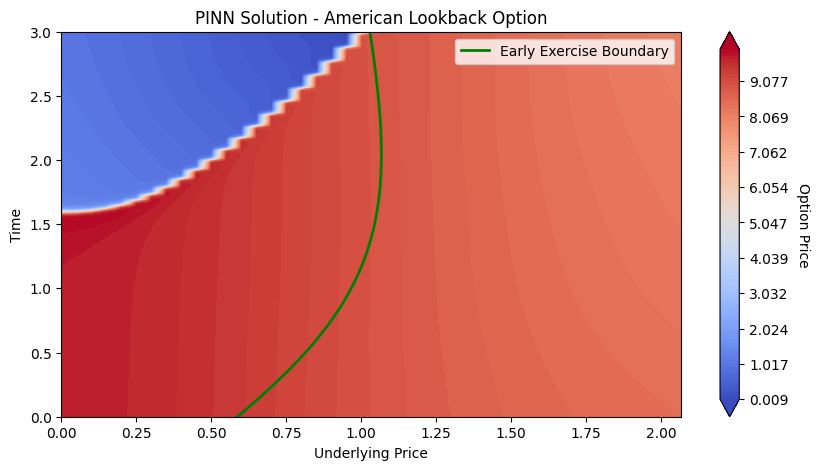

Free Boundary (B_pred): [0.58735144 0.59499687 0.6026057  0.6101761  0.61770695 0.6251965
 0.6326434  0.64004624 0.6474037  0.6547143  0.66197664 0.6691896
 0.6763516  0.68346167 0.6905183  0.6975206  0.70446736 0.7113572
 0.7181893  0.7249626  0.73167586 0.7383284  0.74491894 0.7514468
 0.757911   0.7643109  0.7706455  0.776914   0.78311557 0.78924984
 0.7953161  0.8013135  0.8072416  0.8130999  0.81888777 0.8246047
 0.83025074 0.83582485 0.8413268  0.84675664 0.8521134  0.8573976
 0.8626085  0.86774606 0.8728098  0.87780017 0.8827166  0.8875592
 0.8923279  0.8970227  0.9016436  0.90619075 0.91066396 0.91506356
 0.9193896  0.9236421  0.9278216  0.93192786 0.9359616  0.93992275
 0.9438116  0.94762844 0.95137364 0.95504737 0.9586501  0.9621824
 0.9656444  0.9690367  0.97235966 0.97561365 0.9787991  0.9819168
 0.98496675 0.9879495  0.99086624 0.9937167  0.996502   0.99922204
 1.001878   1.0044703  1.0069996  1.009466   1.0118704  1.0142136
 1.016496   1.0187181  1.0208806  1.0229844  1.0

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Test data preparation with expanded range
X_test = np.linspace(0.0, 15.0, 300).astype(np.float32)  # Expanded asset range
T_test = np.linspace(0, T, 200).astype(np.float32)       # Time range

# Create grid for predictions
X_grid, T_grid = np.meshgrid(X_test, T_test)
X_T_test = np.hstack((X_grid.flatten()[:, np.newaxis], T_grid.flatten()[:, np.newaxis]))

# Check if the models are properly initialized
if not hasattr(my_pinn.mdl, "predict") or not hasattr(my_pinn.fb, "predict"):
    raise ValueError("Models are not properly initialized or trained before prediction.")

# Option price prediction
u_pred = my_pinn.mdl.predict(X_T_test, batch_size=512)  # Predict option prices with batch size
u_pred = np.maximum(u_pred, 0)  # Clip negative values to ensure non-negative option prices
u_pred = u_pred.reshape(X_grid.shape)  # Reshape for grid visualization

# Free boundary prediction
B_pred = my_pinn.fb.predict(T_test[:, np.newaxis], batch_size=512)  # Predict free boundary
B_pred = np.clip(B_pred, np.min(X_test), np.max(X_test))  # Ensure boundary values are within the asset range

# Plot function with corrected ylim setting
def plot_pinn_solution(X, T, U, B, option_type="American Lookback Option", save_path=None):
    
    # X: Grid for underlying prices
    # T: Grid for time points
    # U: Grid for option prices
    # B: Predicted free boundary values
    # option_type: Type of the option (default: "American Lookback Option")
    # save_path: Optional path to save the plot (default: None)
    
    fig, ax = plt.subplots(figsize=(10, 5))

    # Option Pricing
    levels = np.linspace(np.min(U), np.max(U), 100)
    contour = ax.contourf(X, T, U, levels=levels, cmap='coolwarm', extend='both')
    cbar = fig.colorbar(contour)
    cbar.ax.set_ylabel('Option Price', rotation=270, labelpad=15)

    # Free boundary
    ax.plot(B.flatten(), T_test, 'g-', label='Early Exercise Boundary', linewidth=2)

    # Adjust axis limits for better visualization
    ax.set_xlim([0, np.max(B) + 1])  # Limit price range to slightly beyond the boundary
    ax.set_ylim([0, np.max(T_test)])  # Use the maximum value from T_test

    ax.set_xlabel('Underlying Price')
    ax.set_ylabel('Time')
    ax.set_title(f'PINN Solution - {option_type}')
    ax.legend(loc='upper right')

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved at {save_path}")

    plt.show()

# Plot the improved solution with corrected axis limits
plot_pinn_solution(X_grid, T_grid, u_pred, B_pred, save_path="improved_pinn_solution_fixed.png")

# Additional debugging for predicted values
print("Free Boundary (B_pred):", B_pred.flatten())
print("Option Prices (u_pred): Min =", np.min(u_pred), ", Max =", np.max(u_pred))


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Parameters
DTYPE = 'float32'
T = 3.0
r = 0.01
sigma = 0.05
K = 10.0

# PDE for Lookback Option
def pde(tape, S, M, t, u_val, u_S, u_M):
    """PDE for Lookback Options with path-dependent variable M."""
    u_SS = tape.gradient(u_S, S)  # Second derivative w.r.t. S
    u_t = tape.gradient(u_val, t)  # Derivative w.r.t. t

    # PDE residual
    residual = (
        u_t
        + 0.5 * sigma**2 * S**2 * u_SS
        + r * S * u_S
        - r * u_val
    )
    return residual

# Generate paths to track M (minimum/maximum value of S)
def generate_paths(S0, time_steps, batch_size, option_type):
    """Generate paths and compute minimum/maximum based on the option type."""
    dt = T / time_steps
    S_paths = [S0]
    M_paths = [S0]

    for _ in range(1, time_steps):
        dW = tf.random.normal((batch_size, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
        St = S_paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
        S_paths.append(St)

        if "Fixed Call" in option_type:
            Mt = tf.maximum(M_paths[-1], St)  # Maximum of S for Fixed Call
        elif "Fixed Put" in option_type:
            Mt = tf.minimum(M_paths[-1], St)  # Minimum of S for Fixed Put
        elif "Floating Call" in option_type:
            Mt = M_paths[-1]  # M remains constant for Floating Call
        elif "Floating Put" in option_type:
            Mt = M_paths[-1]  # M remains constant for Floating Put
        M_paths.append(Mt)

    return tf.concat(S_paths, axis=1), tf.concat(M_paths, axis=1)

# Payoff functions
def payoff_fixed_call(M_paths):
    return tf.maximum(M_paths[:, -1:] - K, 0.0)

def payoff_fixed_put(M_paths):
    return tf.maximum(K - M_paths[:, -1:], 0.0)

def payoff_floating_call(S_paths, M_paths):
    return tf.maximum(S_paths[:, -1:] - M_paths[:, -1:], 0.0)

def payoff_floating_put(S_paths, M_paths):
    return tf.maximum(M_paths[:, -1:] - S_paths[:, -1:], 0.0)

# Define model
def init_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(1, activation=None),
    ])
    return model

# Loss function
@tf.function
def loss_function(model, S, M, t, payoff, option_type):
    with tf.GradientTape(persistent=True) as tape:
        tape.watch([S, M, t])
        inputs = tf.concat([S, M, t], axis=1)
        u_val = model(inputs)

        # Gradients
        u_S = tape.gradient(u_val, S)
        u_M = tape.gradient(u_val, M)

    # PDE residual
    residual = pde(tape, S, M, t, u_val, u_S, u_M)
    loss_pde = tf.reduce_mean(tf.square(residual))

    # Payoff constraint
    payoff_constraint = tf.maximum(0.0, payoff - u_val)
    loss_payoff = tf.reduce_mean(tf.square(payoff_constraint))

    # Total loss
    total_loss = loss_pde + loss_payoff
    return total_loss

# Training loop
def train_pinn(model, payoff_function, option_type, epochs=5000, batch_size=2000, time_steps=100):
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

    for epoch in range(epochs):
        S0 = tf.random.uniform((batch_size, 1), minval=0.5, maxval=30.0, dtype=DTYPE)
        S_paths, M_paths = generate_paths(S0, time_steps, batch_size, option_type)

        # Reshape inputs for the model
        S = tf.reshape(S_paths, (-1, 1))
        M = tf.reshape(M_paths, (-1, 1))
        t = tf.linspace(0.0, T, time_steps)
        t = tf.tile(t[tf.newaxis, :], [batch_size, 1])
        t = tf.reshape(t, (-1, 1))

        # Compute payoff
        if "Fixed Call" in option_type:
            payoff = payoff_fixed_call(M_paths)
        elif "Fixed Put" in option_type:
            payoff = payoff_fixed_put(M_paths)
        elif "Floating Call" in option_type:
            payoff = payoff_floating_call(S_paths, M_paths)
        elif "Floating Put" in option_type:
            payoff = payoff_floating_put(S_paths, M_paths)
        payoff = tf.reshape(tf.tile(payoff, [1, time_steps]), (-1, 1))

        # Compute loss
        with tf.GradientTape() as tape:
            loss = loss_function(model, S, M, t, payoff, option_type)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

        # Log progress
        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}, Loss: {loss.numpy()}")

# Train for each option type
cases = {
    "Fixed Call": payoff_fixed_call,
    "Fixed Put": payoff_fixed_put,
    "Floating Call": payoff_floating_call,
    "Floating Put": payoff_floating_put,
}

for case_name, payoff_fn in cases.items():
    print(f"Training for {case_name}")
    model = init_model()
    train_pinn(model, payoff_fn, option_type=case_name, epochs=10000, batch_size=1000, time_steps=50)
    print(f"Training completed for {case_name}")

Training for Fixed Call
Epoch 0, Loss: 147.080810546875
Epoch 100, Loss: 15.590998649597168
Epoch 200, Loss: 6.777486324310303
Epoch 300, Loss: 2.9659013748168945
Epoch 400, Loss: 1.2032521963119507
Epoch 500, Loss: 0.8836070895195007
Epoch 600, Loss: 0.5092741847038269
Epoch 700, Loss: 0.3057226836681366
Epoch 800, Loss: 0.25082772970199585
Epoch 900, Loss: 0.09489987790584564
Epoch 1000, Loss: 0.18559080362319946
Epoch 1100, Loss: 0.155012309551239
Epoch 1200, Loss: 0.08657495677471161
Epoch 1300, Loss: 0.09176671504974365
Epoch 1400, Loss: 0.10502690821886063
Epoch 1500, Loss: 0.07440333068370819
Epoch 1600, Loss: 0.06949852406978607
Epoch 1700, Loss: 0.04391297325491905
Epoch 1800, Loss: 0.032742828130722046
Epoch 1900, Loss: 0.012250317260622978
Epoch 2000, Loss: 0.025334512814879417
Epoch 2100, Loss: 0.030926179140806198
